Cargamos metadatos del proyecto

In [1]:
import json
from pathlib import Path 

# Cargar metadatos 
metadata_path = Path("../src/models") / "metadata.json"
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=4, ensure_ascii=False))

IMG_SIZE = metadata["image_size"]
BATCH_SIZE = metadata["batch_size"]
CLASS_NAMES = metadata["class_names"]
NUM_CLASSES = len(CLASS_NAMES)
SEED = metadata["seed"]
MODELOS_DIR = metadata["MODELOS_DIR"]
RESULTS_DIR = metadata["RESULTS_DIR"]
EPOCHS  = metadata["EPOCHS"]
ruta_dataset = metadata["DATASET_DIR"]
ruta_train = ruta_dataset + "/train"
ruta_val = ruta_dataset + "/val"
ruta_test = ruta_dataset + "/test"

{
    "class_names": [
        "1. Enfeksiyonel",
        "2. Ekzama",
        "3. Akne",
        "4. Pigment",
        "5. Benign",
        "6. Malign"
    ],
    "image_size": [
        224,
        224
    ],
    "batch_size": 16,
    "label_mode": "int",
    "seed": 42,
    "tensorflow_version": "2.10.1",
    "EPOCHS": 10,
    "SEED": 42,
    "MODELOS_DIR": "../src/models",
    "RESULTS_DIR": "../src/models/resultados",
    "DATASET_DIR": "../data/processed/"
}


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(SEED)

# Configurar crecimiento dinámico de memoria GPU
# Evita que tf reserve toda la memoria de la GPU al inicio, permitiendo que otros procesos puedan usarla.
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)

        print("Memory growth activado para", len(gpus), "GPU(s)")

    except RuntimeError as e:
        print("Error al configurar memory growth:", e)

else:
    print("No se detectan GPU")


print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Memory growth activado para 1 GPU(s)
TensorFlow: 2.10.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:

NUM_CLASSES = len(CLASS_NAMES)
CLASS_IDS = np.arange(NUM_CLASSES)
MALIGN_IDX = CLASS_NAMES.index("6. Malign")

# Usa la misma resolución que en tu baseline.
IMG_SIZE = (IMG_SIZE[0], IMG_SIZE[1])  # (224, 224)
BATCH_SIZE = BATCH_SIZE

USE_AUGMENTATION = False    
USE_CLASS_WEIGHTS = False

HEAD_EPOCHS = 5
FINE_TUNE_EPOCHS = EPOCHS - HEAD_EPOCHS
HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-5

BEST_MODEL_PATH = Path(MODELOS_DIR) / "mobilenetv2.keras"

assert Path(ruta_train).is_dir(), f"No existe {ruta_train}"
assert Path(ruta_val).is_dir(), f"No existe {ruta_val}"

**Cargar las particiones:** Fijamos el orden de las clases y desactivamos el barajado en validación para mantener alineadas las etiquetas y predicciones. image_dataset_from_directory permite establecer ambos parámetros.

In [4]:
def load_partition(directory, shuffle):
    return keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="int",
        class_names=CLASS_NAMES,
        color_mode="rgb",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_raw = load_partition(ruta_train, shuffle=True)
val_raw = load_partition(ruta_val, shuffle=False)

train_paths = list(train_raw.file_paths)
val_paths = list(val_raw.file_paths)

# Las etiquetas de entrenamiento se usan solamente para contar clases.
y_train = np.concatenate([
    labels.numpy() for _, labels in train_raw
])
y_val = np.concatenate([
    labels.numpy() for _, labels in val_raw
])

distribution = pd.DataFrame({
    "clase": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val": np.bincount(y_val, minlength=NUM_CLASSES),
})
display(distribution)

# Comprueba el soporte del informe original.
expected_val_support = np.array([159, 74, 175, 111, 1014, 823])
actual_val_support = np.bincount(y_val, minlength=NUM_CLASSES)

assert np.array_equal(actual_val_support, expected_val_support), (
    "La distribución de validación no coincide con el baseline. "
    "Revisa la partición y el orden de clases."
)

# Esta comprobación no garantiza que sean las mismas imágenes:
# para eso debes reutilizar la partición original.
pd.DataFrame({
    "path": val_paths,
    "label": y_val,
}).to_csv(Path(RESULTS_DIR) / "validation_manifest.csv", index=False)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)
val_ds = val_raw.prefetch(AUTOTUNE)

Found 25918 files belonging to 6 classes.
Found 2356 files belonging to 6 classes.


,clase,train,val
0,1. Enfeksiyonel,3830,159
1,2. Ekzama,2539,74
2,3. Akne,2063,175
3,4. Pigment,995,111
4,5. Benign,9770,1014
5,6. Malign,6721,823


Calculamos los pesos de las clases. (No se usan porque en la comparación del baseline con el primer experimento Macro F1 del dataset validacion dio mejor resultado sin DataAugmentation ni ClassWeigths)

In [5]:
assert np.all(np.bincount(y_train, minlength=NUM_CLASSES) > 0), (
    "Faltan clases en entrenamiento."
)

if USE_CLASS_WEIGHTS:
    weights = compute_class_weight(
        class_weight="balanced",
        classes=CLASS_IDS,
        y=y_train,
    )
    class_weights = {
        int(class_id): float(weight)
        for class_id, weight in zip(CLASS_IDS, weights)
    }
else:
    class_weights = None

print("Class weights:", class_weights)

Class weights: None


Compilamos el modelo. Lo hacemos sin Data Augmentation, pero está preparado para hacerlo poniendo USE_AUGMENTATION a True

In [6]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05, fill_mode="reflect"),
    layers.RandomZoom(0.10, fill_mode="reflect"),
], name="augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = augmentation(inputs) if USE_AUGMENTATION else inputs
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenet_preprocessing",
)(x)

# Mantiene BatchNormalization en modo inferencia.
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_probabilities",
)(x)

model = keras.Model(inputs, outputs, name="MobileNetV2_skin")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=HEAD_LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()

Model: "MobileNetV2_skin"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 image (InputLayer)          [(None, 224, 224, 3)]     0         
                                                                 
 mobilenet_preprocessing (Re  (None, 224, 224, 3)      0         
 scaling)                                                        
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                  

Seleccionamos el mejor checkponit por macro F1

In [7]:
class ValidationMacroF1(keras.callbacks.Callback):
    def __init__(self, dataset, y_true, save_path):
        super().__init__()
        self.dataset = dataset
        self.y_true = np.asarray(y_true)
        self.save_path = str(save_path)
        self.best = -np.inf
        self.records = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}

        probabilities = self.model.predict(self.dataset, verbose=0)
        predictions = probabilities.argmax(axis=1)

        macro_f1 = f1_score(
            self.y_true,
            predictions,
            labels=CLASS_IDS,
            average="macro",
            zero_division=0,
        )

        logs["val_macro_f1"] = float(macro_f1)
        self.records.append({
            "validation_check": len(self.records) + 1,
            "val_macro_f1": float(macro_f1),
        })

        print(f" — val_macro_f1: {macro_f1:.4f}")

        if macro_f1 > self.best:
            self.best = float(macro_f1)
            self.model.save(self.save_path)
            print(f"   Mejor checkpoint guardado: {macro_f1:.4f}")


macro_callback = ValidationMacroF1(
    dataset=val_ds,
    y_true=y_val,
    save_path=BEST_MODEL_PATH,
)

print(f"Modelo guardado en: {BEST_MODEL_PATH}")
print(f"Tamaño: {BEST_MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

def make_callbacks():
    # macro_callback debe ir antes de los callbacks que leen val_macro_f1.
    return [
        macro_callback,
        keras.callbacks.EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            patience=5,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_macro_f1",
            mode="max",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]

Modelo guardado en: ..\src\models\mobilenetv2.keras
Tamaño: 20.55 MB


Entrenamos la cabeza

In [8]:
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
)

Epoch 1/5
1620/1620 [==============================] - ETA: 0s - loss: 0.9905 - accuracy: 0.6058 — val_macro_f1: 0.6133
   Mejor checkpoint guardado: 0.6133
1620/1620 [==============================] - 85s 49ms/step - loss: 0.9905 - accuracy: 0.6058 - val_loss: 0.7141 - val_accuracy: 0.7199 - val_macro_f1: 0.6133 - lr: 0.0010
Epoch 2/5
1620/1620 [==============================] - ETA: 0s - loss: 0.8737 - accuracy: 0.6527 — val_macro_f1: 0.6401
   Mejor checkpoint guardado: 0.6401
1620/1620 [==============================] - 78s 48ms/step - loss: 0.8737 - accuracy: 0.6527 - val_loss: 0.6966 - val_accuracy: 0.7309 - val_macro_f1: 0.6401 - lr: 0.0010
Epoch 3/5
1620/1620 [==============================] - ETA: 0s - loss: 0.8548 - accuracy: 0.6596 — val_macro_f1: 0.6449
   Mejor checkpoint guardado: 0.6449
1620/1620 [==============================] - 79s 49ms/step - loss: 0.8548 - accuracy: 0.6596 - val_loss: 0.7083 - val_accuracy: 0.7390 - val_macro_f1: 0.6449 - lr: 0.0010
Epoch 4/5
1620/1

Fine-tuning

In [9]:
model = keras.models.load_model(BEST_MODEL_PATH)

base_model = next(
    layer for layer in model.layers
    if isinstance(layer, keras.Model)
    and "mobilenet" in layer.name.lower()
)

base_model.trainable = True

# Entrenar solo las últimas 30 capas, excepto BatchNormalization.
for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

# Es necesario recompilar tras cambiar qué capas son entrenables.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
)

print("Mejor macro F1 de ambas fases:", macro_callback.best)

Epoch 1/5
1620/1620 [==============================] - 98s 59ms/step - loss: 0.7410 - accuracy: 0.7009 - val_loss: 0.6229 - val_accuracy: 0.7517 - val_macro_f1: 0.6409 - lr: 1.0000e-05
Epoch 2/5
1620/1620 [==============================] - ETA: 0s - loss: 0.6444 - accuracy: 0.7420 — val_macro_f1: 0.6795
   Mejor checkpoint guardado: 0.6795
1620/1620 [==============================] - 94s 58ms/step - loss: 0.6444 - accuracy: 0.7420 - val_loss: 0.5631 - val_accuracy: 0.7848 - val_macro_f1: 0.6795 - lr: 1.0000e-05
Epoch 3/5
1620/1620 [==============================] - ETA: 0s - loss: 0.5770 - accuracy: 0.7734 — val_macro_f1: 0.6810
   Mejor checkpoint guardado: 0.6810
1620/1620 [==============================] - 96s 59ms/step - loss: 0.5770 - accuracy: 0.7734 - val_loss: 0.5438 - val_accuracy: 0.7899 - val_macro_f1: 0.6810 - lr: 1.0000e-05
Epoch 4/5
1620/1620 [==============================] - ETA: 0s - loss: 0.5189 - accuracy: 0.7969 — val_macro_f1: 0.6975
   Mejor checkpoint guardado: 0

Evaluar mejor modelo

In [10]:
best_model = keras.models.load_model(BEST_MODEL_PATH)

probabilities = best_model.predict(val_ds, verbose=1)
y_pred = probabilities.argmax(axis=1)

print(classification_report(
    y_val,
    y_pred,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

recall_per_class = recall_score(
    y_val,
    y_pred,
    labels=CLASS_IDS,
    average=None,
    zero_division=0,
)

new_metrics = {
    "accuracy": float(accuracy_score(y_val, y_pred)),
    "macro_f1": float(f1_score(
        y_val, y_pred,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0,
    )),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, y_pred)
    ),
    "recall_malign": float(recall_per_class[MALIGN_IDX]),
}

for name, value in new_metrics.items():
    print(f"{name}: {value:.6f}")

report = classification_report(
    y_val,
    y_pred,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report).T.to_csv(
    Path(RESULTS_DIR) / "classification_report.csv"
)

prediction_table = pd.DataFrame({
    "path": val_paths,
    "y_true": y_val,
    "y_pred": y_pred,
})
for idx, class_name in enumerate(CLASS_NAMES):
    prediction_table[f"prob_{class_name}"] = probabilities[:, idx]

prediction_table.to_csv(
    Path(RESULTS_DIR) / "validation_predictions.csv",
    index=False,
)

with open(Path(RESULTS_DIR) / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(new_metrics, f, indent=2, ensure_ascii=False)

148/148 [==============================] - 7s 41ms/step
                 precision    recall  f1-score   support

1. Enfeksiyonel     0.4535    0.7673    0.5701       159
      2. Ekzama     0.4521    0.4459    0.4490        74
        3. Akne     0.8735    0.8286    0.8504       175
     4. Pigment     0.9048    0.5135    0.6552       111
      5. Benign     0.8711    0.8994    0.8850      1014
      6. Malign     0.8645    0.7752    0.8174       823

       accuracy                         0.8094      2356
      macro avg     0.7366    0.7050    0.7045      2356
   weighted avg     0.8292    0.8094    0.8131      2356

accuracy: 0.809423
macro_f1: 0.704520
balanced_accuracy: 0.704991
recall_malign: 0.775213


In [15]:

# Nombre del modelo experimental
MODEL_PATH = Path(MODELOS_DIR) / "mobilenetv2.keras"

# Guardar el modelo completo
model.save(MODEL_PATH)

print(f"Modelo guardado en: {MODEL_PATH}")
print(f"Tamaño: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

Modelo guardado en: ..\src\models\mobilenetv2.keras
Tamaño: 20.55 MB


**Matrices de confusión.**
La segunda matriz permite ver el porcentaje de aciertos y errores dentro de cada clase, sin que el tamaño de Benign o Malign eclipse las demás.


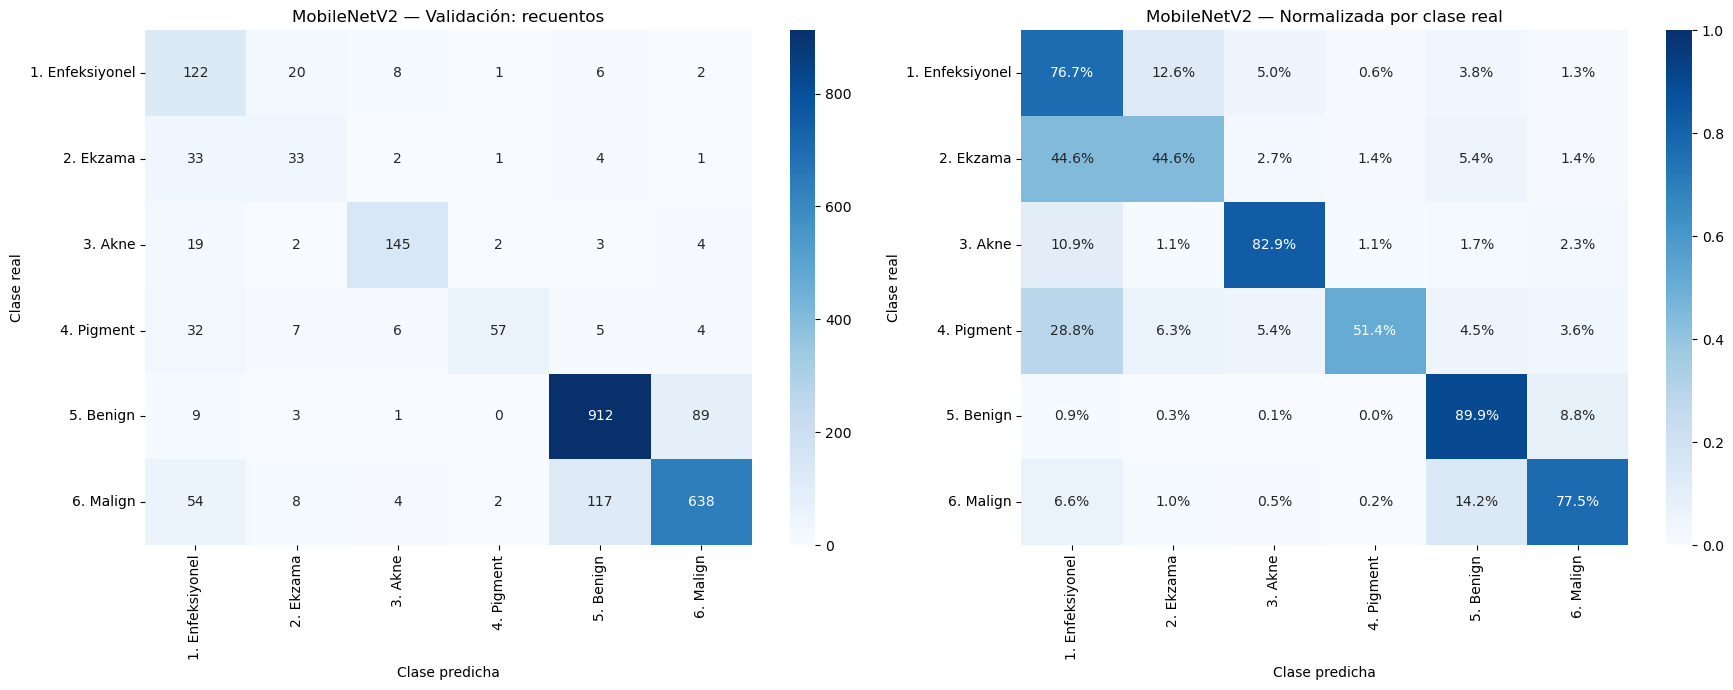

In [12]:
cm = confusion_matrix(y_val, y_pred, labels=CLASS_IDS)
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0],
)
axes[0].set_title("MobileNetV2 — Validación: recuentos")

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1],
)
axes[1].set_title("MobileNetV2 — Normalizada por clase real")

for ax in axes:
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / "confusion_matrices.png", dpi=160)
plt.show()

Actualizamos el fichero de resultados anteriores con los de este modelo para poder comparar con otros experimentos.

In [19]:
from sklearn.metrics import precision_score, recall_score

# Ajusta esta ruta respecto al directorio de ejecución del notebook.
PREVIOUS_RESULTS_PATH = Path(RESULTS_DIR) / "comparativa_modelos.csv"

# Comprobamos que existe el fichero.
if not PREVIOUS_RESULTS_PATH.is_file():
    raise FileNotFoundError(
        f"No se encuentra el CSV: {PREVIOUS_RESULTS_PATH.resolve()}"
    )

previous_results = pd.read_csv(PREVIOUS_RESULTS_PATH)

metric_columns = [
    "accuracy",
    "macro_f1",
    "balanced_accuracy",
    "precision_malign",
    "recall_malign",
]

required_columns = ["modelo", "archivo"] + metric_columns

# Añadimos las columnas que falten, inicializadas a NaN.
new_columns = [
    col for col in ["precision_malign","recall_malign"]
    if col not in previous_results.columns
]

if new_columns:
    for col in new_columns:
        previous_results[col] = np.nan

    # Actualizamos el CSV.
    previous_results.to_csv(PREVIOUS_RESULTS_PATH, index=False)

    print(f"Columnas añadidas al CSV: {new_columns}")

# Comprobamos que el esquema ya es correcto.
missing_columns = set(required_columns) - set(previous_results.columns)

if missing_columns:
    raise ValueError(
        f"Faltan columnas en el CSV: {sorted(missing_columns)}"
    )

# Completamos las métricas de MobileNetV2.
# Se calculan todas las clases para que la posición de Malign sea explícita.
class_ids = np.arange(len(CLASS_NAMES))
malign_idx = CLASS_NAMES.index("6. Malign")

precision_per_class = precision_score(
    y_val,
    y_pred,
    labels=class_ids,
    average=None,
    zero_division=0,
)

recall_per_class = recall_score(
    y_val,
    y_pred,
    labels=class_ids,
    average=None,
    zero_division=0,
)

mobilenet_results = pd.DataFrame([{
    "modelo": "MobileNetV2",
    "archivo": str(BEST_MODEL_PATH),
    "accuracy": float(new_metrics["accuracy"]),
    "macro_f1": float(new_metrics["macro_f1"]),
    "balanced_accuracy": float(new_metrics["balanced_accuracy"]),
    "recall_malign": float(recall_per_class[malign_idx]),
    "precision_malign": float(precision_per_class[malign_idx]),
}])

mobilenet_results.to_csv(
    f"{PREVIOUS_RESULTS_PATH}",
    mode="a",
    header=False,
    index=False
)

# 3. Guardar también MobileNetV2 por separado.
# Este archivo permitirá comparar desde otro notebook.
mobilenet_csv = Path(RESULTS_DIR) / "mobilenetv2_metricas_val.csv"
mobilenet_csv.parent.mkdir(parents=True, exist_ok=True)

mobilenet_results.to_csv(mobilenet_csv, index=False)